In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import xarray as xr
from tqdm.auto import tqdm

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
import src.horizontal_regions as regions

plt.style.use('seaborn-v0_8-paper')

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [6]:
df_at3d = pd.DataFrame()

## This is really slow bc of
## 1) Concat on every loop
## 2) Double merge
## 3) Late filter (drop extinction <= 0.3 earlier)
## My thinking (todo) is to put the labeled clouds into the dataframe
## Then, I can group by label for each altitude and calculate cloud area 
## & compare to in situ chord length
for r in tqdm(list(exset.retrievals.values())):
    tmp_cld = r.solvers_retrieval[0.67].medium['cloud'].copy(deep=True)
    # labels, _ = regions.label_per_slice(tmp_cld.extinction.data > 0.3)
    # tmp_cld['labels'] = (['x', 'y', 'z'], labels)
    tmp_df = tmp_cld.extinction.to_dataframe()
    tmp_df['source'] = r.exp_name
    tmp_vc = xr.load_dataset(r.root_dir / 'min_optical_path.nc').min_optical_path.to_dataframe()
    tmp_df = pd.merge(
        tmp_df.reset_index().loc[:,['x','y','z','extinction','source']], 
        tmp_vc.reset_index().loc[:,['x','y','z','min_optical_path']], 
        on=['x','y','z']
    )
    # tmp_df = pd.merge(
    #     tmp_df.reset_index().loc[:,['x','y','z','extinction','source', 'min_optical_path']], 
    #     tmp_cld.to_dataframe().reset_index().loc[:,['x','y','z','labels']], 
    #     on=['x','y','z']
    # )
    df_at3d = pd.concat([df_at3d, tmp_df[tmp_df['extinction'] > 0.3]])

df_at3d = df_at3d.reset_index()
df_at3d['x'] *= 1000
df_at3d['y'] *= 1000
df_at3d['z'] *= 1000
df_at3d['isVeiled'] = df_at3d['min_optical_path'] >= 5

  0%|          | 0/6 [00:00<?, ?it/s]

FileNotFoundError: [Errno 2] No such file or directory: b'/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/default/min_optical_path.nc'

In [4]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
df_p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
df_p3['source'] = 'in situ'

# The sample at time t is part of the cloud element e if
# the extinction at time t > 0.3 
# and there is another sample t' \in e such that |t-t'| < 3
# In other words, it takes 3 seconds of clear air to separate two clouds
df_p3['sample_optical_path'] = df_p3['ext_km'] * df_p3['Length_m'] * 1e-3
ext_th = 0.3
t_th = pd.Timedelta(3, 's')
df_p3['cloud_pass'] = -1
cloud_pass = 1
inCloud = False
t_last_cloud = df_p3.index[0]
for row in df_p3.itertuples():
    if(not inCloud):
        if(row.ext_km > ext_th):
            inCloud = True
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
    else:
        if(row.ext_km > ext_th):
            t_last_cloud = row.Index
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        elif(row.Index - t_last_cloud < t_th):
            df_p3.at[row.Index, 'cloud_pass'] = cloud_pass
        else:
            df_p3.loc[t_last_cloud+pd.Timedelta(1, 's'):row.Index, 'cloud_pass'] = -1
            inCloud = False
            cloud_pass += 1

g = df_p3.groupby('cloud_pass')['sample_optical_path']
df_p3['forward_optical_path'] = g.cumsum()
df_p3['backward_optical_path'] = g.apply(lambda s: s[::-1].cumsum()[::-1]).reset_index(level=0, drop=True)
df_p3['optical_path'] = df_p3[['forward_optical_path', 'backward_optical_path']].min(axis=1)
df_p3['pass_length'] = df_p3.groupby('cloud_pass')['Length_m'].transform('sum')
df_p3['isVeiled'] = df_p3['optical_path'] >= 5

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)
/tmp/ipykernel_2194099/3987540596.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['cloud_pass'] = -1
/tmp/ipykernel_2194099/3987540596.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_p3['forward_optical_path'] = g.cumsum()
/tmp/ipykernel_2194099/3987540596.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result o

In [5]:
# bins = np.arange(350, 1251, 100)
bins = np.arange(-50, 1451, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)
df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)

NameError: name 'df_at3d' is not defined

In [7]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

df_p3_sub = df_p3[
    # (p3['N_L'] > 10000)
    (df_p3['ext_km'] > 0.3)
    & (df_p3.index > start_time)
    & (df_p3.index < end_time)
    & (df_p3['GPS_Altitude'] < 1250)
    # & (p3['optical_path'] < 5)       # Remove P3 veiled core
    # & (p3['pass_length'] < 3600)
    & ~(
        ((df_p3.index >= pd.to_datetime('2019-10-02 00:35:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 00:36:00')))
        | ((df_p3.index >= pd.to_datetime('2019-10-02 01:45:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 01:46:30')))
    )
]
df_p3_sub = df_p3_sub.reset_index().rename(columns={'ext_km':'extinction'})

<Axes: ylabel='Frequency'>

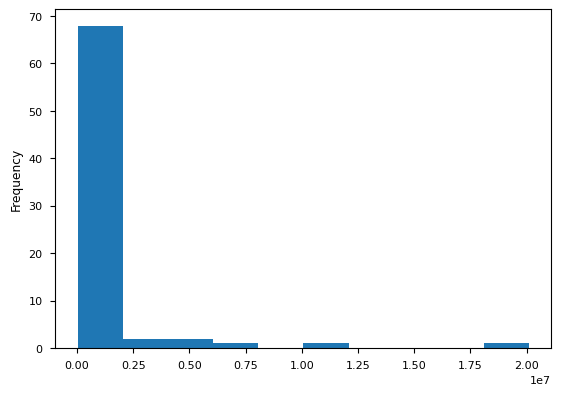

In [19]:
(np.pi * (0.5 * df_p3_sub.drop_duplicates(subset='cloud_pass')['pass_length'])**2).plot.hist()

In [8]:
df_p3_at3d = pd.concat([
    df_at3d.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled']],
    df_p3_sub.loc[:, ['extinction', 'altitude_bin', 'source', 'isVeiled']] #.groupby('altitude_bin').filter(lambda x: len(x) > 10)
])

In [9]:
for i, name in enumerate(exset.retrievals.keys()):
    print(f'{i}: {name}')

0: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH
1: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained
2: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf
3: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_mod
4: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic
5: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150
6: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250
7: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22
8: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54
9: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast
10: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast_unconstrained
11: /data/gdi/b/johntl3/LundstromPub2025/e

/tmp/ipykernel_3234671/3342329076.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_3234671/3342329076.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == False].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_3234671/3342329076.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to

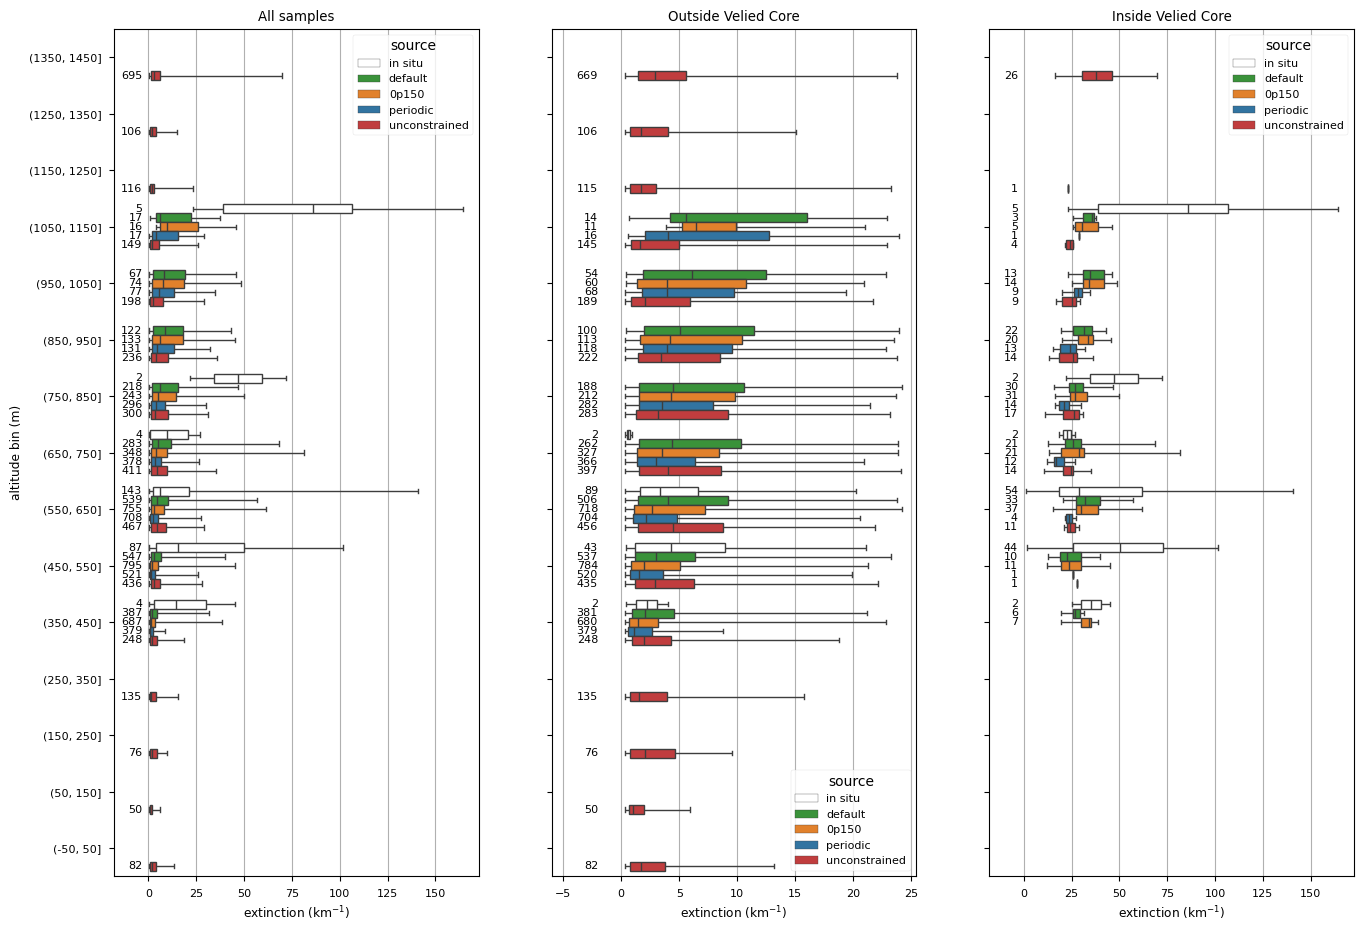

In [10]:
pltlist = ['in situ', 'default', '0p150', 'periodic', 'unconstrained']
# pltlist = ['in situ', 'default', '0p150']

box_kwargs = {
    'x': 'extinction',
    'y': 'altitude_bin',
    'hue': 'source',
    'hue_order': pltlist,
    'palette': {
        'in situ': 'white',
        'default': 'tab:green',
        'periodic': 'tab:blue',
        'unconstrained': 'tab:red',
        '0p150': 'tab:orange'
    },
    'order': [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)],
    'whis':(0, 100),
}

f, ax = plt.subplots(1, 3, figsize=(16,11), sharex=False, sharey=True)
sns.boxplot(df_p3_at3d[df_p3_at3d['source'].isin(pltlist)], ax=ax[0], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[0].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[0].set_xlim(-18, None)
ax[0].set_ylabel('altitude bin (m)')
ax[0].set_xlabel(r'extinction (km$^{-1}$)')
ax[0].set_title('All samples')
ax[0].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == False)], ax=ax[1], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == False].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[1].text(-2, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[1].set_xlim(-6, None)
# ax[1].set_ylabel('altitude bin (m)')
ax[1].set_xlabel(r'extinction (km$^{-1}$)')
ax[1].set_title('Outside Velied Core')
ax[1].grid(axis='x')

sns.boxplot(df_p3_at3d[(df_p3_at3d['source'].isin(pltlist)) & (df_p3_at3d['isVeiled'] == True)], ax=ax[2], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d[df_p3_at3d['isVeiled'] == True].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[2].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[2].set_xlim(-18, None)
# ax[1].set_ylabel('altitude bin (m)')
ax[2].set_xlabel(r'extinction (km$^{-1}$)')
ax[2].set_title('Inside Velied Core')
ax[2].grid(axis='x')